# Educación e ingresos en México
## ¿Estudiar más se relaciona con ganar más?

**Análisis exploratorio con datos abiertos de México**  
**Autores:** Luis David Gonzalez Romero y Diego Alberto Ortega Carreto  
**Fuente:** ENIGH 2024, Nueva Serie, INEGI. **Elaboración:** 25 de octubre de 2026.

Este proyecto estudia la asociación entre escolaridad e ingreso monetario corriente del
trabajo principal. Compara un modelo con escolaridad sola y modelos con otros factores,
estima intervalos de confianza y evalúa predicción en grupos reservados.

**La población de estudio no incluye a todos los mexicanos:** se delimita a integrantes
del hogar de 25 a 64 años con un solo trabajo subordinado remunerado en México,
ingreso positivo y jornada válida. El resultado es asociativo, no causal.

## 1. Pregunta, objetivo e hipótesis

**Pregunta:** dentro de la población delimitada, ¿se mantienen diferencias de ingreso por
escolaridad al considerar edad, jornada, sexo, ámbito rural y entidad federativa?

**Objetivo:** cuantificar esas diferencias mediante regresión ponderada e intervalos de
confianza, para describir brechas educativas y laborales con datos oficiales mexicanos.

**Hipótesis conjunta:** $H_0$: todos los contrastes de escolaridad frente a secundaria son
cero; $H_1$: al menos uno difiere. Se adopta $\alpha=0.05$.

La comparación de referencia es **secundaria**. No se interpretan categorías escolares
como si fueran años numéricos equivalentes.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown
import pandas as pd
import numpy as np
from src import analysis as a
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Raíz del proyecto:", ROOT.name)

Raíz del proyecto: educacion-ingresos-mexico-github


## 2. Fuente y descarga reproducible

Se utilizan las tablas **Población**, **Trabajos** e **Ingresos**. Los ZIP originales
permanecen intactos; el manifiesto conserva enlaces, tamaños y huellas SHA-256.
Las uniones usan `folioviv`, `foliohog` y `numren` como texto.

Si los datos aún no existen, ejecutar `python scripts/download_data.py` desde la raíz.
La descarga requiere conexión a Internet; el análisis posterior es local.

- [Programa y microdatos](https://www.inegi.org.mx/programas/enigh/nc/2024/)
- [Descripción de la base](https://www.inegi.org.mx/contenidos/programas/enigh/nc/2024/microdatos/889463924494.pdf)
- [Diseño muestral](https://www.inegi.org.mx/contenidos/programas/enigh/nc/2024/doc/889463924517.pdf)

In [2]:
from scripts.download_data import download
if not all((ROOT/f"data/raw/{t}.csv").exists() for t in ["poblacion", "trabajos", "ingresos"]):
    download()
display(pd.DataFrame(json.loads((ROOT/"data/source_manifest.json").read_text(encoding="utf-8")))[["file", "bytes", "sha256"]])

,file,bytes,sha256
0,poblacion.zip,9055376,37fbd07c29a5e9971c0d3f6bdb89af47cb89e530069240...
1,ingresos.zip,4292608,0974630476c65e604e0c95e68e565e72d8de542f6720eb...
2,trabajos.zip,1928668,46337a2e8eb52eaeb43508b5a3b9c1967c3af39402d10a...
3,descripcion_base.pdf,2967447,1b0c698594da41bfe8c976c5d161dcdf99ae4f962a8a5c...
4,diseno_muestral.pdf,1626755,2d2a5c0fd47a92d7c2d044300b47cf15330f9902c8b509...


## 3. Definición de variables y muestra

| Variable | Construcción y significado |
|---|---|
| Ingreso mensual | Suma de `ing_tri` para P001–P007, dividida entre 3; ingreso monetario corriente del trabajo principal, MXN |
| Log ingreso | Logaritmo natural del ingreso positivo; respuesta de las regresiones |
| Escolaridad | Nivel máximo con grados aprobados; puede estar incompleto |
| Edad | Edad menos 40 y su cuadrado; permite una relación curva con el log ingreso |
| Jornada | Logaritmo de horas semanales del trabajo principal; se admiten 1–168 |
| Mujer | `sexo=2`, según codificación del cuestionario; referencia `sexo=1` |
| Rural | Tercer dígito de `folioviv=6`, según el diccionario del INEGI |
| Entidad | Indicadores de entidad federativa |
| Ocupación | Gran división: primer dígito de SINCO; solo en modelo de sensibilidad |
| Peso, estrato y UPM | `factor`, `entidad + est_dis` y `entidad + upm` |

P001–P007 incluyen sueldo/destajo, comisiones, horas extra, incentivos, bonos y primas.
Se excluyen aguinaldo/utilidades del ejercicio 2023, trabajos secundarios, negocios y
transferencias. No se confunde esta medida con el ingreso total del hogar.

Los niveles técnicos y normales se conservan en una categoría separada por sus
antecedentes diversos. No se supone que una licenciatura reportada esté terminada.
Se usan observaciones completas, sin imputar el objetivo ni eliminar extremos por IQR.

In [3]:
df, descriptivos, modelos, coeficientes, validacion, resultados = a.run()
display(pd.read_csv(a.TABLES/"calidad_fuentes.csv"))
display(pd.read_csv(a.TABLES/"auditoria_muestra.csv"))

Muestra analítica: 76407


{
  "pregunta": "¿Estudiar más se relaciona con ganar más en México?",
  "fuente": "ENIGH 2024 Nueva Serie, INEGI",
  "n": 76407,
  "n_poblacion_fuente": 308598,
  "personas_expandidas_dominio": 34437734,
  "media_mensual_ponderada": 11892.279149419548,
  "mediana_mensual_ponderada": 9782.606666666667,
  "r2_log_ajustado": 0.3922668342707756,
  "diseno": {
    "upm": 10569,
    "estratos": 681,
    "gl_diseno": 9888,
    "estratos_unitarios": 0
  },
  "prueba_escolaridad": {
    "F": 995.0729201502803,
    "gl_num": 6,
    "gl_den": 9888,
    "p": 0.0
  },
  "validacion": {
    "n_train": 60765,
    "n_test": 15642,
    "upm_train": 8343,
    "upm_test": 2086,
    "upm_compartidas": 0,
    "semilla": 2026
  },
  "efectos_educacion": [
    {
      "educacion": "Sin primaria",
      "diferencia_pct": -24.686100910207774,
      "pct_inf": -28.446763014507738,
      "pct_sup": -20.72778765749665,
      "p": 2.8643550145518915e-27
    },
    {
      "educacion": "Primaria",
      "diferenci

,tabla,filas,duplicados_exactos,celdas_ausentes
0,poblacion_seleccion,308598,0,438895
1,trabajos_seleccion,164325,0,41168
2,ingresos_seleccion,391563,0,0


,etapa,n,excluidos_en_etapa
0,Personas de la tabla Población,308598,0
1,Edad entre 25 y 64 años,152798,155800
2,Un solo trabajo declarado,102439,50359
3,"Principal subordinado, remunerado y en México",76476,25963
4,Ingreso principal monetario positivo (P001-P007),76407,69
5,"Horas semanales válidas, entre 1 y 168",76407,0
6,Escolaridad y diseño observados,76407,0
7,Integrantes del hogar (sin huéspedes ni servic...,76407,0


## 4. Auditoría de la muestra y del diseño

Los faltantes de variables que no aplican en el cuestionario no se tratan como errores
automáticos. La auditoría registra el número excluido en cada filtro. Cada persona
debe tener un único trabajo principal y una sola fila final.

Los factores de expansión se usan como **pesos de encuesta**, no como inversas de
la varianza. WLS resuelve el ajuste ponderado; su covarianza clásica no se utiliza
para la inferencia principal. La covarianza de Taylor agrega scores por UPM y los
centra dentro de cada estrato. Se conserva el marco completo con scores cero para
UPM sin personas del dominio. No se aplica corrección de población finita.

In [4]:
assert not df.duplicated(a.KEY).any()
assert df.ingreso_mensual.gt(0).all()
assert df.htrab.between(1, 168).all()
assert df.edad.between(25, 64).all()
display(pd.Series(resultados["diseno"], name="Diseño"))
print("Personas observadas en el dominio:", f"{len(df):,}")
print("Población expandida del dominio:", f"{df.factor.sum():,.0f}")

upm                   10569
estratos                681
gl_diseno              9888
estratos_unitarios        0
Name: Diseño, dtype: int64

Personas observadas en el dominio: 76,407
Población expandida del dominio: 34,437,734


## 5. Distribución del ingreso

La media y la mediana son ponderadas. La transformación logarítmica permite expresar
las diferencias escolares como razones de ingreso y reduce la influencia de la escala
en pesos. No garantiza normalidad ni varianza constante. La primera gráfica se limita
a P99 para facilitar la lectura; **el modelo principal conserva toda la cola superior**.

Media mensual (MXN)     11,892.2791
Mediana mensual (MXN)    9,782.6067
dtype: float64

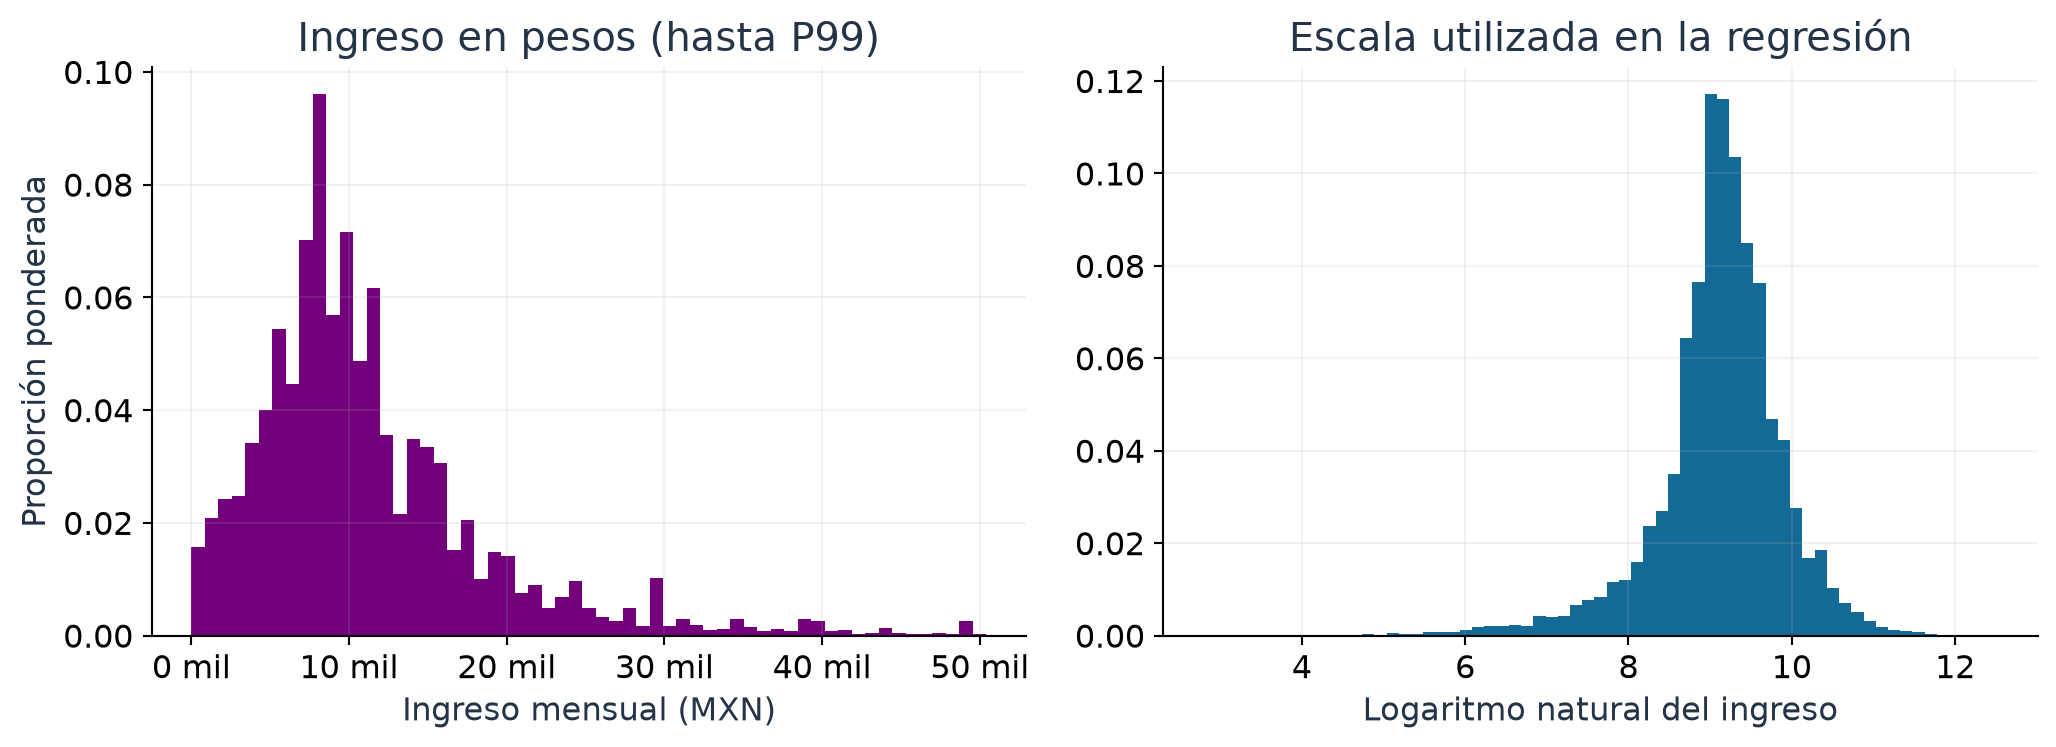

In [5]:
display(pd.Series({"Media mensual (MXN)": resultados["media_mensual_ponderada"],
                   "Mediana mensual (MXN)": resultados["mediana_mensual_ponderada"]}))
display(Image(filename=str(a.FIGURES/"01_distribucion.png")))

## 6. Ingreso observado según escolaridad

Las barras muestran medias ponderadas con IC del 95% de Taylor para la media.
Son diferencias descriptivas entre grupos que también pueden diferir en edad,
ocupación, jornada y ubicación. Los cuartiles son cuantiles ponderados y no intervalos
de confianza.

,educacion,n,personas_expandidas,media_mensual,mediana_mensual,q1_mensual,q3_mensual,ic95_media_inf,ic95_media_sup
0,Sin primaria,1358,500887,"6,099.1580","5,869.5633","3,203.8033","7,868.8500","5,819.9545","6,378.3615"
1,Primaria,12507,4671958,"7,513.7062","7,081.9667","4,565.2167","9,782.6067","7,383.2612","7,644.1513"
2,Secundaria,23691,9586411,"8,900.2424","8,109.8867","5,869.5633","11,241.7533","8,796.3653","9,004.1196"
3,Media superior,16770,7900830,"10,569.5253","9,374.9967","6,847.8233","12,815.2167","10,419.9781","10,719.0726"
4,Técnica o normal,2328,1163493,"11,764.0391","10,271.7367","7,278.6867","14,754.0967","11,301.9141","12,226.1641"
5,Licenciatura,17608,9392060,"16,686.4290","13,695.6500","9,377.0467","19,672.1300","16,330.0056","17,042.8525"
6,Posgrado,2145,1222095,"26,305.4123","19,672.1300","13,695.6500","31,141.3000","24,689.8609","27,920.9637"


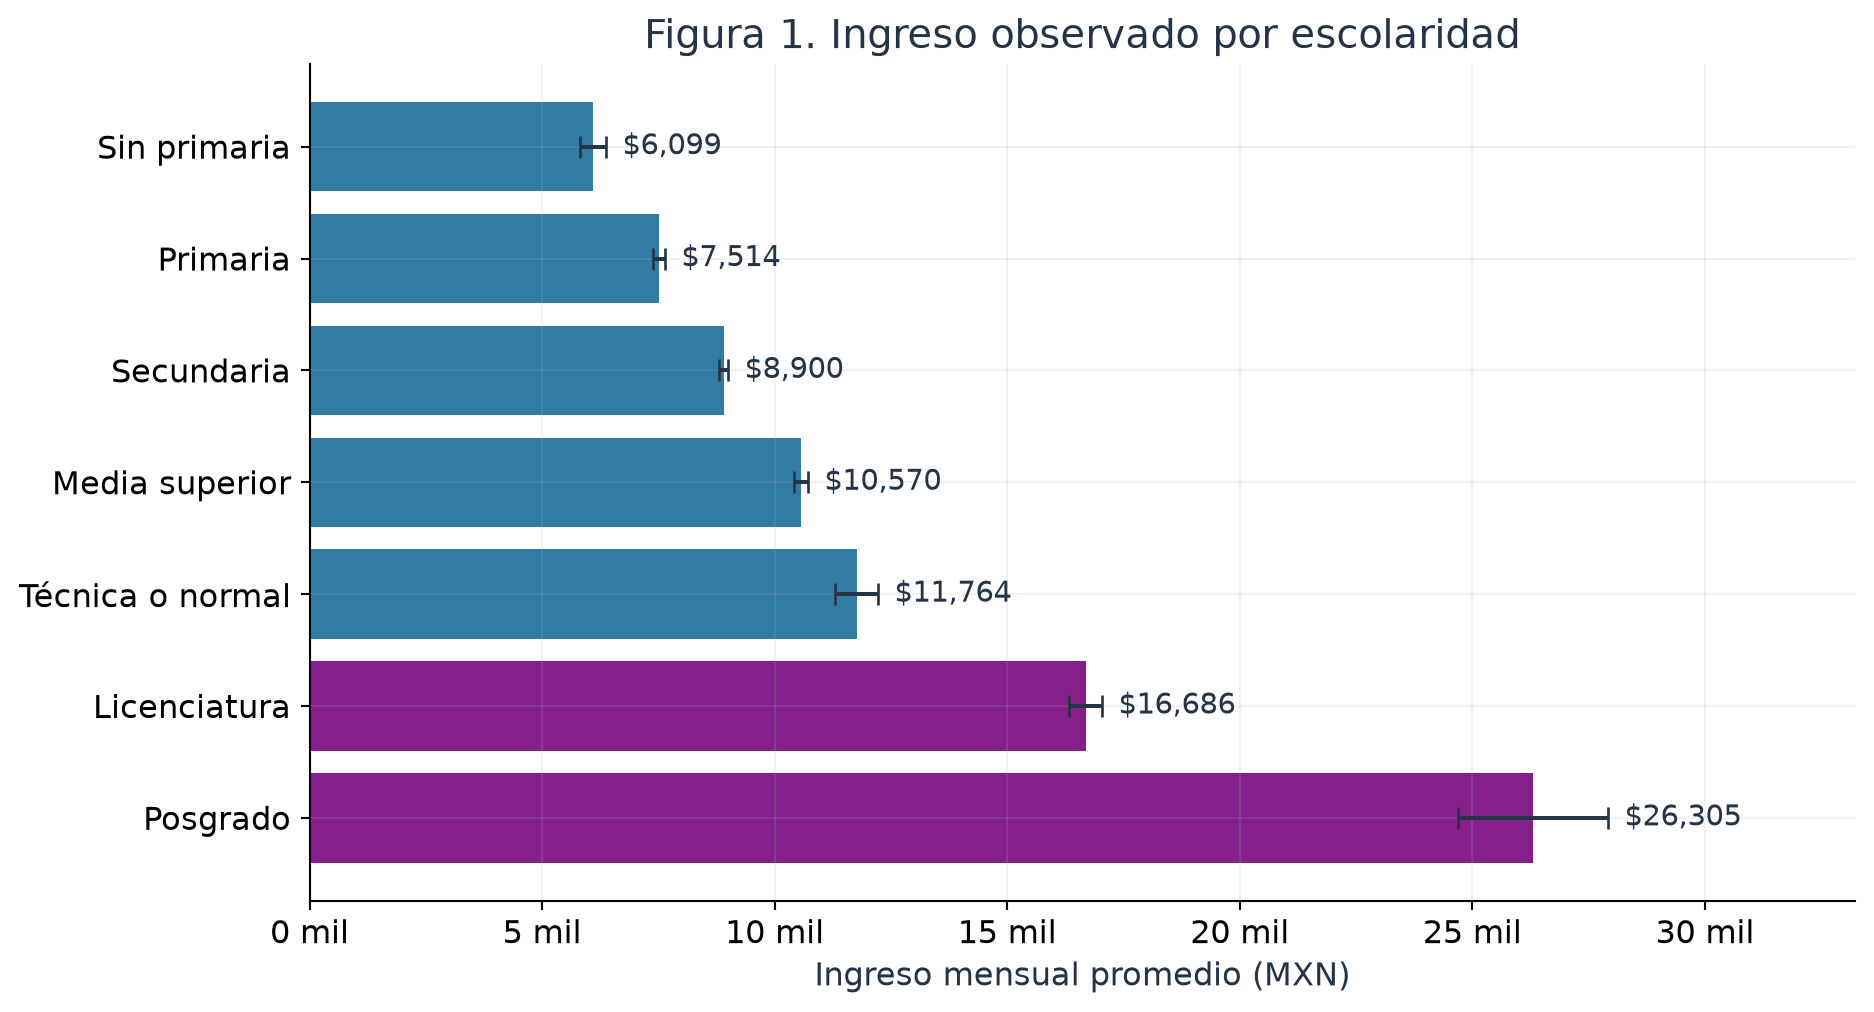

In [6]:
display(descriptivos)
display(Image(filename=str(a.FIGURES/"02_ingreso_escolaridad.png")))

## 7. Especificación de la regresión

Modelo principal:

$$\log(Y_i)=\beta_0+\sum_g\beta_g I(E_i=g)+\beta_1(A_i-40)
+\beta_2(A_i-40)^2+\beta_3\log(H_i)+\beta_4 M_i+\beta_5 R_i
+\sum_s\gamma_s I(S_i=s)+\varepsilon_i.$$

El ajuste minimiza $\sum_i w_i(y_i-X_i\beta)^2$. Para un nivel escolar,
$100[\exp(\beta_g)-1]$ es la diferencia porcentual de la media geométrica condicional
frente a secundaria; no es directamente una diferencia de medias aritméticas en pesos.
Se transforman también ambos límites del intervalo.

El tercer modelo agrega ocupación como sensibilidad. La ocupación podría formar parte
del mecanismo que vincula educación e ingreso; incluirla cambia la comparación y no
"elimina" por sí sola el sesgo de confusión.

In [7]:
display(pd.DataFrame({"Modelo": list(a.FORMULAS), "Fórmula": list(a.FORMULAS.values())}))
display(pd.read_csv(a.TABLES/"comparacion_ajuste.csv"))
display(coeficientes["Modelo ajustado"])
display(pd.read_csv(a.TABLES/"efectos_ajustados.csv")[["educacion","diferencia_pct","pct_inf","pct_sup","p"]])

,Modelo,Fórmula
0,Escolaridad sola,"log_ingreso ~ C(educacion, Treatment(reference..."
1,Modelo ajustado,"log_ingreso ~ C(educacion, Treatment(reference..."
2,Con ocupación,"log_ingreso ~ C(educacion, Treatment(reference..."


,modelo,n,parametros,r2_ponderada_log,r2_ajustada_log,condicion
0,Escolaridad sola,76407,7,0.1692,0.1692,9.2913
1,Modelo ajustado,76407,43,0.3923,0.3919,"8,355.2138"
2,Con ocupación,76407,52,0.4396,0.4393,"66,360.3152"


,termino,coef,error_estandar,t,p,ic95_inf,ic95_sup
0,Intercept,6.8279,0.0552,123.7310,0.0000,6.7198,6.9361
1,"C(educacion, Treatment(reference='Secundaria')...",-0.2835,0.0261,-10.8492,0.0000,-0.3347,-0.2323
2,"C(educacion, Treatment(reference='Secundaria')...",-0.1336,0.0105,-12.7366,0.0000,-0.1542,-0.1131
3,"C(educacion, Treatment(reference='Secundaria')...",0.1853,0.0090,20.6210,0.0000,0.1677,0.2029
4,"C(educacion, Treatment(reference='Secundaria')...",0.3140,0.0209,15.0494,0.0000,0.2731,0.3549
5,"C(educacion, Treatment(reference='Secundaria')...",0.6632,0.0105,63.3427,0.0000,0.6427,0.6838
6,"C(educacion, Treatment(reference='Secundaria')...",1.1156,0.0246,45.3661,0.0000,1.0674,1.1638
7,C(entidad)[T.02],0.2897,0.0192,15.1199,0.0000,0.2521,0.3272
8,C(entidad)[T.03],0.1552,0.0218,7.1110,0.0000,0.1124,0.1980
9,C(entidad)[T.04],-0.2714,0.0230,-11.7818,0.0000,-0.3166,-0.2263


,educacion,diferencia_pct,pct_inf,pct_sup,p
0,Sin primaria,-24.6861,-28.4468,-20.7278,0.0000
1,Primaria,-12.5080,-14.2889,-10.6901,0.0000
2,Media superior,20.3588,18.2572,22.4977,0.0000
3,Técnica o normal,36.8936,31.4072,42.6091,0.0000
4,Licenciatura,94.1061,90.1628,98.1312,0.0000
5,Posgrado,205.1475,190.7869,220.2173,0.0000


## 8. Intervalos y prueba conjunta

La covarianza de Taylor permite que la dispersión de los errores sea distinta y contempla
la agrupación de la muestra por UPM. Los IC se construyen con t y grados de libertad
UPM menos estratos. Si hay estratos con una UPM, se registra el ajuste de centrado global.
La prueba Wald conjunta examina todos los contrastes escolares a la vez.

Los valores p que aparecen como 0.0000 por redondeo o límites de precisión deben leerse
como p &lt; 0.0001; no como probabilidades exactamente nulas.

No rechazar una hipótesis no demuestra igualdad. Los IC del 95% se refieren al
procedimiento de estimación, no a una probabilidad posterior del parámetro.

,F,gl_num,gl_den,p
0,995.0729,6,9888,0.0000


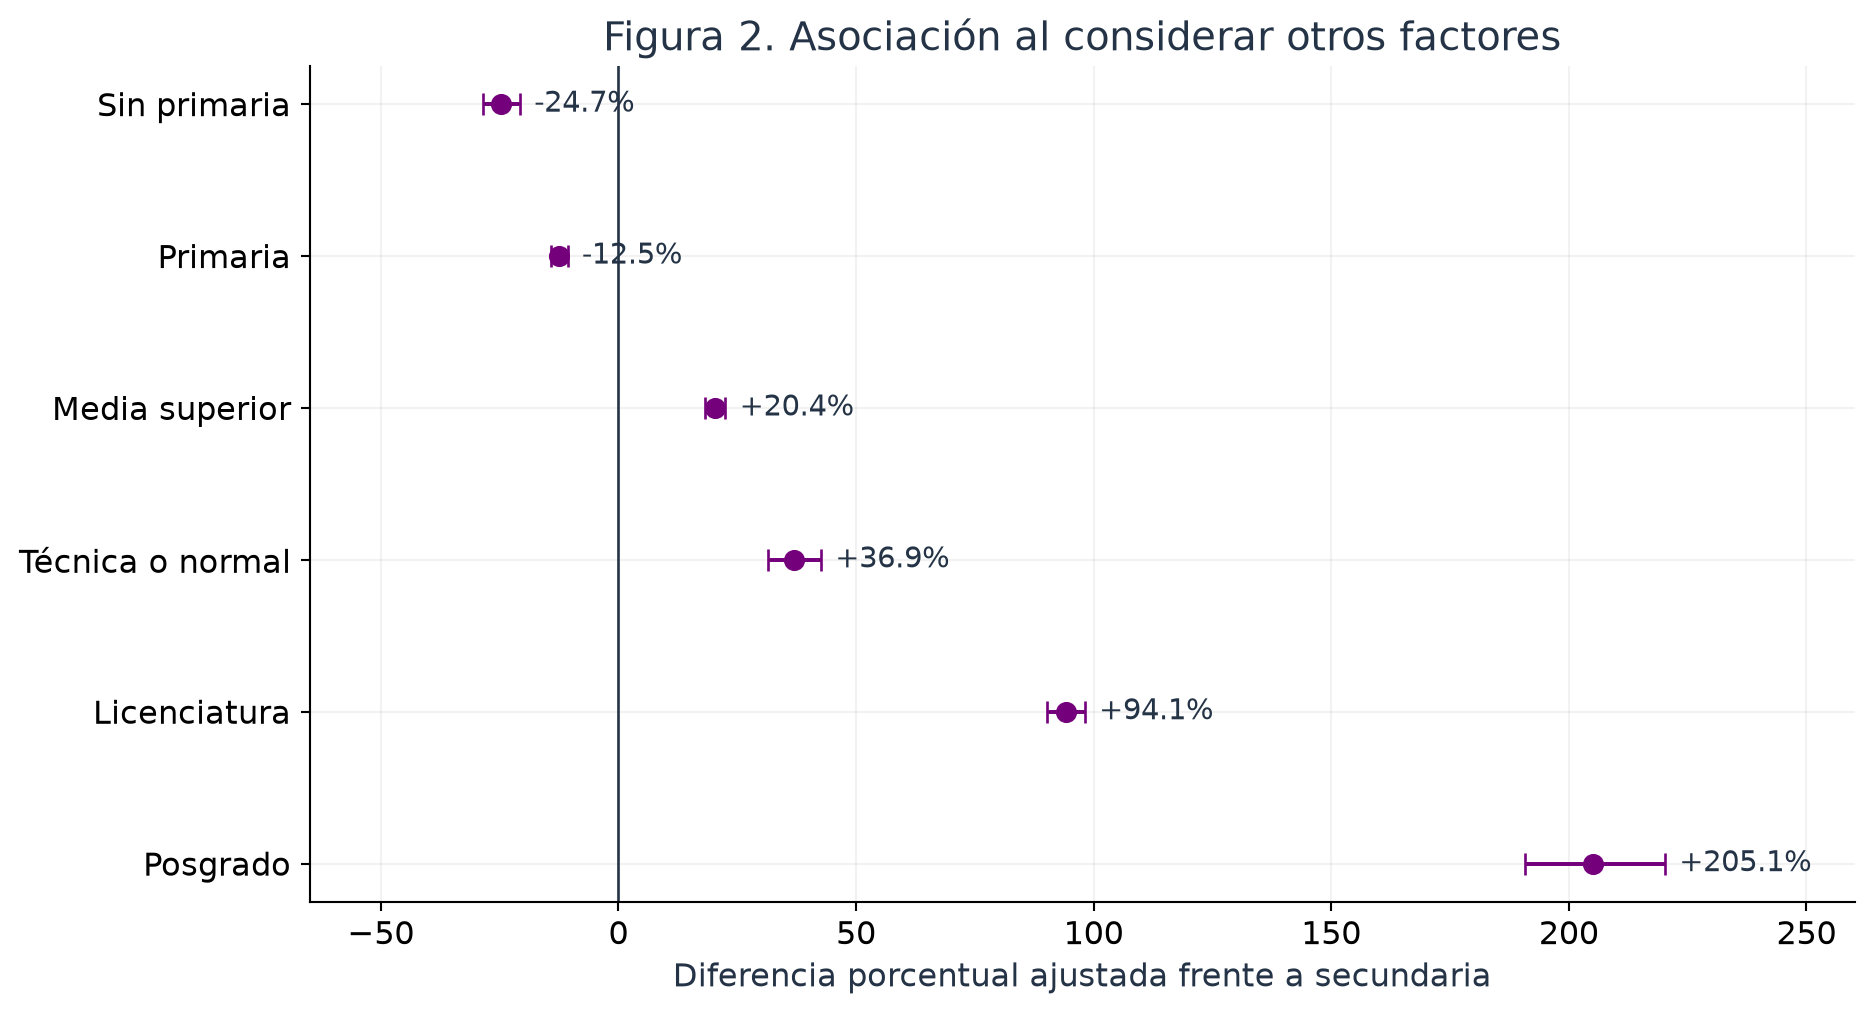

In [8]:
display(pd.DataFrame([resultados["prueba_escolaridad"]]))
display(Image(filename=str(a.FIGURES/"03_efectos_ajustados.png")))

## 9. Diagnóstico y sensibilidad

Se agrega una salida OLS clásica como contraste exploratorio. Breusch–Pagan
y Jarque–Bera se reportan como diagnósticos exploratorios de ese ajuste; sus valores p
clásicos no incorporan el diseño de encuesta. La inferencia principal permanece en la
tabla con covarianza Taylor. El orden de filas no es temporal: Durbin–Watson no permite
concluir dependencia temporal en estos datos.

La sensibilidad sin el 1% superior se compara con el modelo completo y no reemplaza
silenciosamente la muestra principal.

breusch_pagan_LM                                           2,706.2690
breusch_pagan_p                                                0.0000
jarque_bera                                              104,203.7443
jarque_bera_p                                                  0.0000
asimetria                                                     -1.3262
curtosis_Pearson                                               8.0691
durbin_watson                                                  1.7626
alcance             Diagnósticos clásicos OLS exploratorios; sus p...
dtype: object

,termino,pct_completo,pct_sin_1pct_superior,umbral_p99
0,"C(educacion, Treatment(reference='Secundaria')...",-24.6861,-24.5559,"50,414.8300"
1,"C(educacion, Treatment(reference='Secundaria')...",-12.5080,-12.2870,"50,414.8300"
2,"C(educacion, Treatment(reference='Secundaria')...",20.3588,19.8864,"50,414.8300"
3,"C(educacion, Treatment(reference='Secundaria')...",36.8936,36.4119,"50,414.8300"
4,"C(educacion, Treatment(reference='Secundaria')...",94.1061,87.8039,"50,414.8300"
5,"C(educacion, Treatment(reference='Secundaria')...",205.1475,174.9456,"50,414.8300"


,educacion,diferencia_pct,pct_inf,pct_sup
0,Sin primaria,-17.9684,-22.0168,-13.7098
1,Primaria,-8.1729,-9.9875,-6.3217
2,Media superior,13.3704,11.4120,15.3632
3,Técnica o normal,18.6258,14.2200,23.2016
4,Licenciatura,51.7659,48.5228,55.0798
5,Posgrado,112.0380,102.2217,122.3308


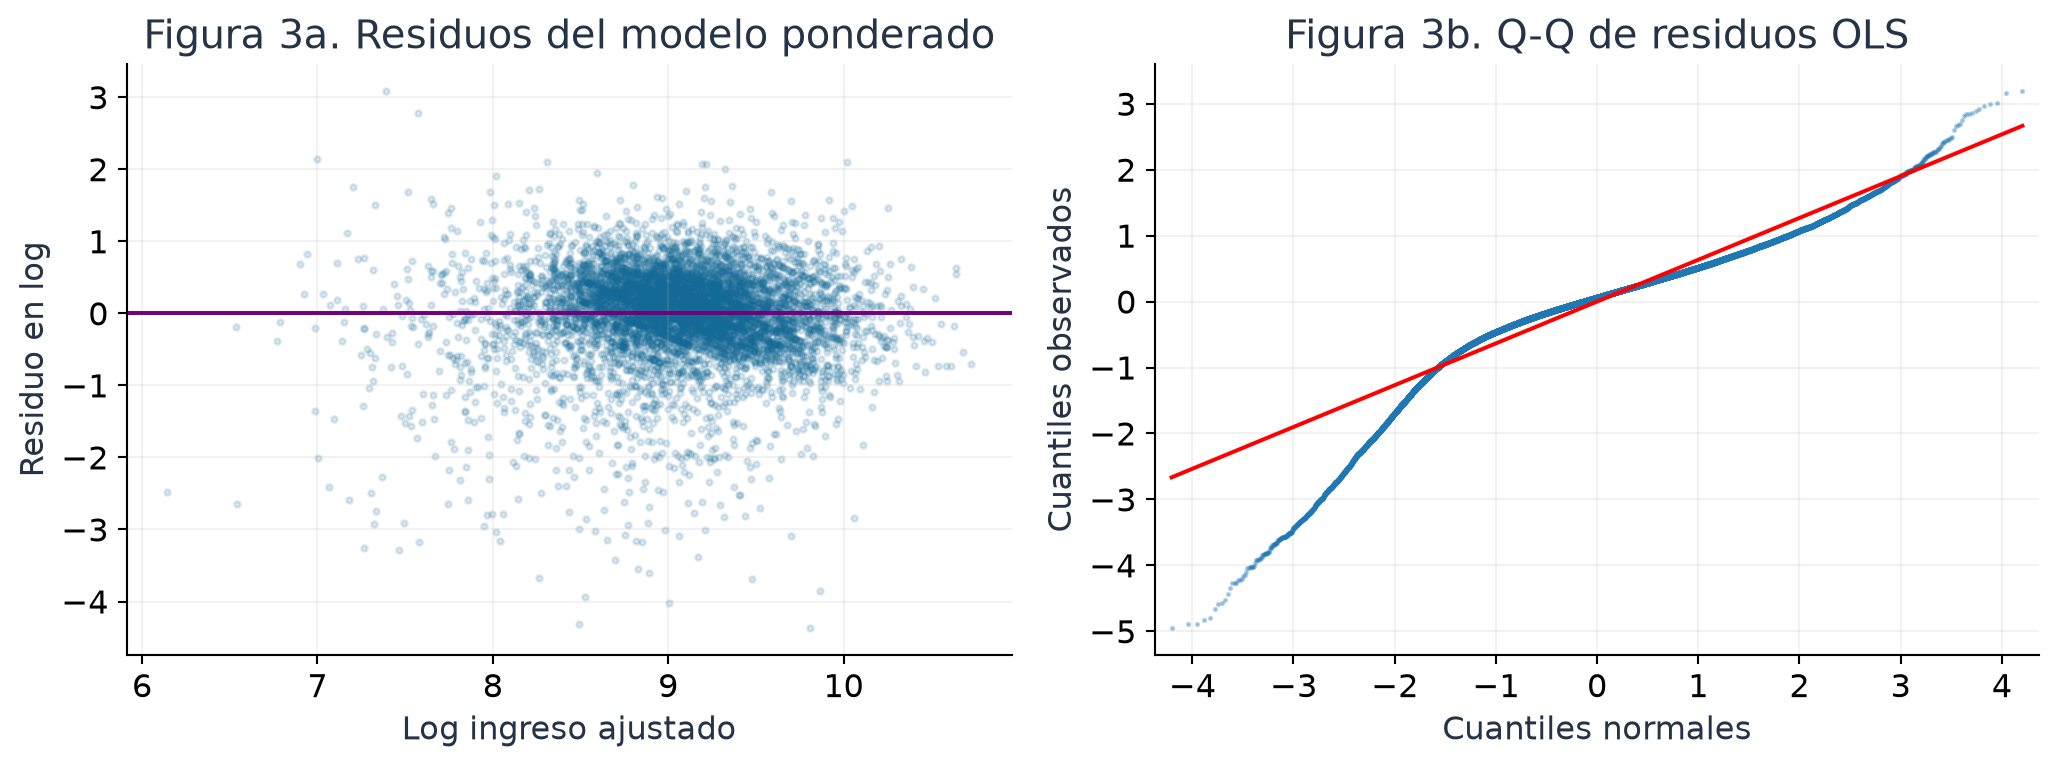

In [9]:
diagnosticos=json.loads((ROOT/"outputs/diagnosticos.json").read_text(encoding="utf-8"))
display(pd.Series(diagnosticos))
display(pd.read_csv(a.TABLES/"sensibilidad_extremos.csv"))
display(pd.read_csv(a.TABLES/"efectos_ocupacion.csv")[["educacion","diferencia_pct","pct_inf","pct_sup"]])
display(Image(filename=str(a.FIGURES/"04_diagnosticos.png")))

## 10. Evaluación en observaciones reservadas

Se reserva aproximadamente 20% de las UPM con semilla 2026; una UPM completa pertenece
a entrenamiento o a prueba. Los coeficientes y la corrección de retrans­formación se
estiman exclusivamente en entrenamiento. Se compara con predecir la media ponderada
de entrenamiento para todas las personas.

Se reportan MAE, RMSE y R² ponderados en pesos, además de RMSE en log. La conversión
de log a pesos utiliza el factor global de Duan calculado con los residuos de entrenamiento;
es una aproximación y puede ser insuficiente si la dispersión depende de los predictores.
La evaluación es interna a esta encuesta; no acredita desempeño en otros años.

n_train            60765
n_test             15642
upm_train           8343
upm_test            2086
upm_compartidas        0
semilla             2026
dtype: int64

,modelo,n_entrenamiento,n_prueba,mae_pesos,rmse_pesos,r2_prueba_pesos,rmse_log
0,Media de entrenamiento,60765,15642,"6,431.1333","12,020.8795",-0.0007,0.8135
1,Escolaridad sola,60765,15642,"5,676.1631","10,996.4464",0.1626,0.7359
2,Modelo ajustado,60765,15642,"5,180.6470","10,428.8985",0.2468,0.6309
3,Con ocupación,60765,15642,"4,882.8632","9,915.3039",0.3192,0.6033


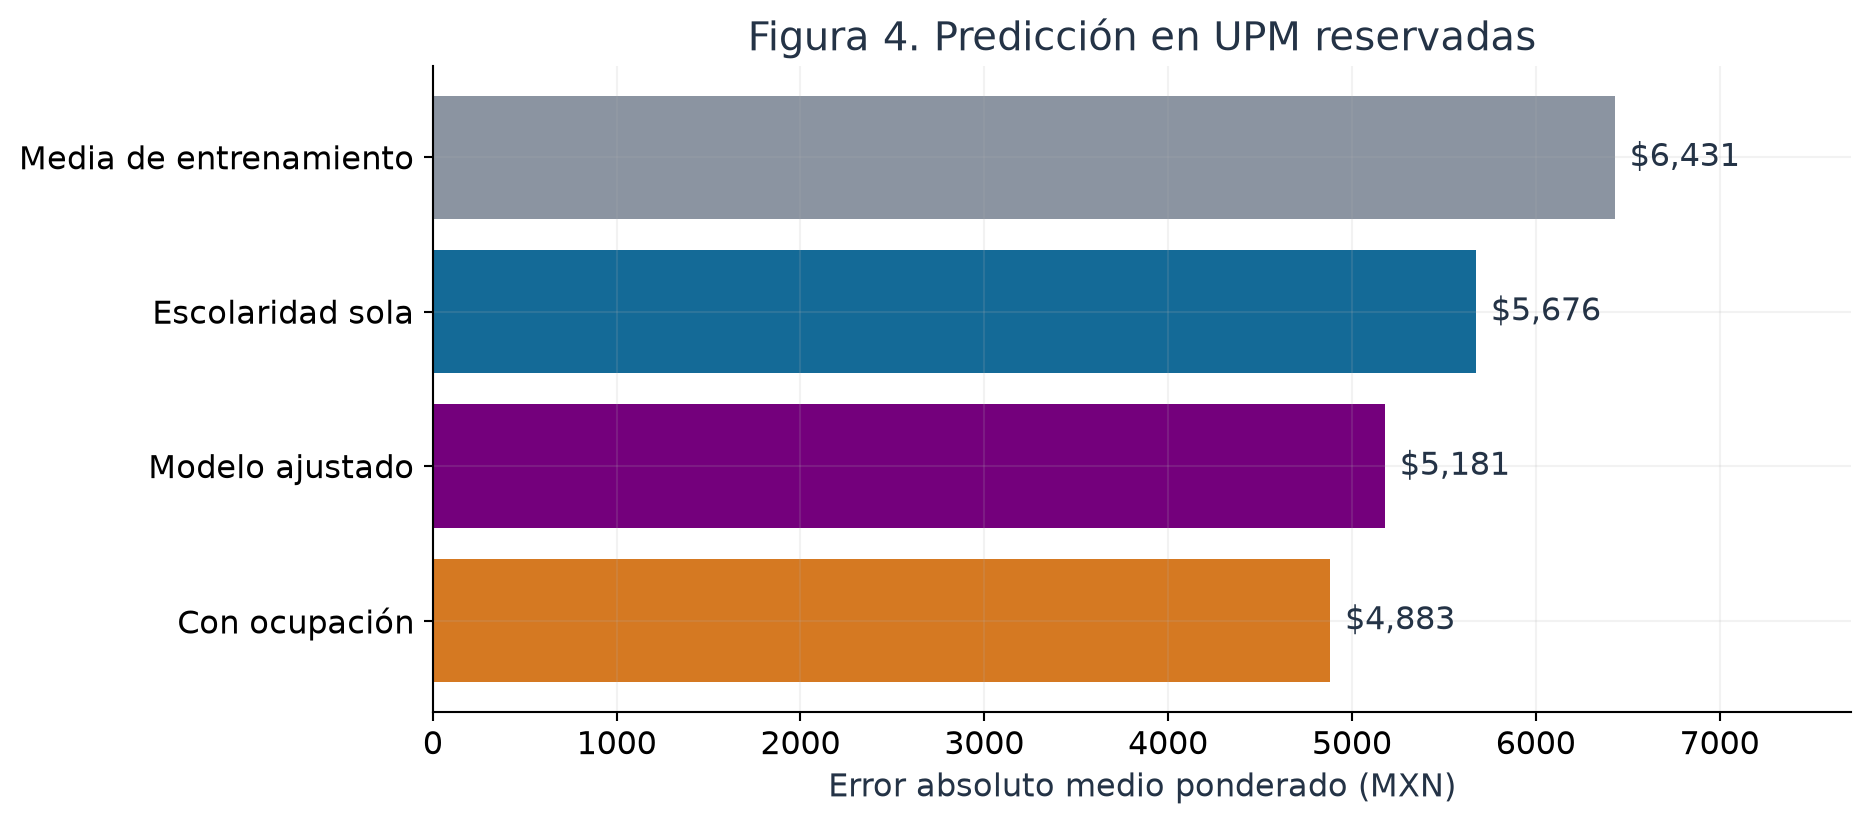

In [10]:
display(pd.Series(resultados["validacion"]))
display(validacion)
display(Image(filename=str(a.FIGURES/"05_validacion.png")))

## 11. Síntesis de resultados

La siguiente síntesis se forma con los resultados de esta ejecución. El resumen visual
utiliza las mismas tablas y gráficas de este cuaderno.

In [11]:
lic=next(x for x in resultados["efectos_educacion"] if x["educacion"]=="Licenciatura")
display(Markdown(f"""En **{resultados['n']:,} personas observadas**, la categoría licenciatura presenta
una diferencia ajustada de **{lic['diferencia_pct']:+.1f}%** frente a secundaria,
con IC95% **[{lic['pct_inf']:.1f}%, {lic['pct_sup']:.1f}%]** en ingreso geométrico condicional.
El R² ponderado del modelo ajustado en escala logarítmica es **{resultados['r2_log_ajustado']:.3f}**.
Estos resultados describen a la población delimitada y no identifican el efecto causal de estudiar."""))

En **76,407 personas observadas**, la categoría licenciatura presenta
una diferencia ajustada de **+94.1%** frente a secundaria,
con IC95% **[90.2%, 98.1%]** en ingreso geométrico condicional.
El R² ponderado del modelo ajustado en escala logarítmica es **0.392**.
Estos resultados describen a la población delimitada y no identifican el efecto causal de estudiar.

## 12. Límites e interpretación

- Se observa solo a personas con un empleo subordinado remunerado e ingreso positivo.
  No se estima acceso al empleo, desempleo ni el beneficio total de una trayectoria escolar.
- Escolaridad indica el nivel con grados aprobados; puede estar incompleto. Técnica/normal
  reúne trayectorias distintas. No se atribuye una duración escolar inventada.
- Edad no equivale a experiencia laboral. No se observan todas las diferencias de habilidad,
  calidad educativa, historia familiar ni selección ocupacional.
- El ingreso trimestral mensualizado y las horas de la semana habitual tienen periodos
  de referencia distintos; la relación no es una contabilidad de salario por hora exacta.
- El diseño es transversal. Las diferencias ajustadas son asociaciones y no garantizan
  aumentos individuales de ingreso al obtener un grado.
- El ajuste de encuesta es una aproximación de Taylor con reemplazo. Los resultados son
  elaboración propia, no tabulados oficiales del INEGI.
- R² mide ajuste en una escala específica, no porcentaje de exactitud de un salario.

## Referencias

Instituto Nacional de Estadística y Geografía. (2025). *Encuesta Nacional de Ingresos y
Gastos de los Hogares 2024, Nueva Serie* [Microdatos]. https://www.inegi.org.mx/programas/enigh/nc/2024/

Instituto Nacional de Estadística y Geografía. (2025). *ENIGH 2024: Descripción de la base de datos*.
https://www.inegi.org.mx/contenidos/programas/enigh/nc/2024/microdatos/889463924494.pdf

Instituto Nacional de Estadística y Geografía. (2025). *ENIGH 2024: Diseño muestral*.
https://www.inegi.org.mx/contenidos/programas/enigh/nc/2024/doc/889463924517.pdf

statsmodels. (s. f.). *Weighted least squares and regression diagnostics*.
https://www.statsmodels.org/stable/regression.html

scikit-learn. (s. f.). *GroupShuffleSplit*.
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html

In [12]:
display(pd.Series(json.loads((ROOT/"outputs/entorno.json").read_text(encoding="utf-8"))))
print("Tablas:", len(list(a.TABLES.glob("*.csv"))))
print("Gráficas PNG:", len(list(a.FIGURES.glob("*.png"))))

python          3.12.14
numpy             2.5.4
pandas            3.1.0
scipy            1.18.1
statsmodels      0.15.0
matplotlib       3.11.2
scikit-learn      1.9.1
nbformat         5.11.1
dtype: str

Tablas: 14
Gráficas PNG: 5
